# 04 · Avaliação final: modelos clássicos e redes neurais

Este notebook **apenas lê** os artefatos gerados pelos comandos das etapas 6 a 8 (`src.lof_experiments`, `src.final_calibration`, `src.neural`, `src.final_evaluation`). Ele não treina, não recalibra e não reavalia nada, para que o teste continue sendo usado uma única vez.

Protocolo (igual para os 7 modelos):
- ajuste somente nas 256 boas de desenvolvimento;
- limiar calibrado nas 64 boas reservadas (FPR-alvo de 5%);
- avaliação única nas 160 imagens de teste (41 boas, 119 defeituosas em 5 categorias);
- defeito é a classe positiva; **falso negativo = parafuso defeituoso aprovado**.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
AVAL = ROOT / 'results/stage8/test_evaluation_v1'
res = json.loads((AVAL / 'test_evaluation.json').read_text())
print('Critério:', res['criterio'])
print('Classes no teste:', res['classes'])

Critério: Menor número de falsos negativos; desempate: maior especificidade, depois maior AUC.
Classes no teste: {'good': 41, 'manipulated_front': 24, 'scratch_head': 24, 'scratch_neck': 25, 'thread_side': 23, 'thread_top': 23}


## Calibração final (64 boas reservadas)

In [2]:
pastas = {'svm': 'stage5/final_svm_v1', 'knn': 'stage5/final_knn_v1',
          'mahalanobis': 'stage5/final_mahalanobis_v1', 'isolation_forest': 'stage5/final_isolation_forest_v1',
          'lof': 'stage6/final_lof_v1', 'patchcore': 'stage7/final_patchcore_v1',
          'autoencoder': 'stage7/final_autoencoder_v1'}
linhas = []
for nome, pasta in pastas.items():
    m = json.loads((ROOT / 'results' / pasta / 'final_calibration.json').read_text())
    linhas.append({'modelo': nome, 'n_ajuste': m['n_fit'], 'n_calibracao': m['n_calibration'],
                   'limiar': m['threshold'], 'fpr_calibracao': m['calibration_fpr'],
                   'teste_acessado': m['test_accessed']})
pd.DataFrame(linhas)

,modelo,n_ajuste,n_calibracao,limiar,fpr_calibracao,teste_acessado
0,svm,256,64,-8.068642,0.046875,False
1,knn,256,64,29.884123,0.046875,False
2,mahalanobis,256,64,2154.539402,0.046875,False
3,isolation_forest,256,64,0.458550,0.046875,False
4,lof,256,64,1.126074,0.046875,False
5,patchcore,256,64,0.936738,0.046875,False
6,autoencoder,256,64,0.010200,0.046875,False


## Resultado no teste (ordenado por falsos negativos)

In [3]:
resumo = pd.read_csv(AVAL / 'summary.csv')
resumo

,posicao,modelo,familia,representacao,tp,fn,tn,fp,recall_defeitos,especificidade,precisao,acuracia,auc,recall_manipulated_front,recall_scratch_head,recall_scratch_neck,recall_thread_side,recall_thread_top,pos_hoc_fp_para_zero_fn,pos_hoc_recall_espec95
0,1,patchcore,rede neural,imagem,106,13,38,3,0.8908,0.9268,0.9725,0.9000,0.9641,0.8333,0.8333,0.96,0.8261,1.0000,16,0.8319
1,2,knn,clássico,R3,25,94,36,5,0.2101,0.8780,0.8333,0.3812,0.6510,0.2083,0.2917,0.24,0.0870,0.2174,41,0.0924
2,3,isolation_forest,clássico,R1,19,100,38,3,0.1597,0.9268,0.8636,0.3563,0.6341,0.2083,0.1667,0.28,0.0435,0.0870,38,0.1597
3,4,lof,clássico,R2,15,104,38,3,0.1261,0.9268,0.8333,0.3312,0.6218,0.1667,0.0833,0.24,0.0435,0.0870,41,0.1092
4,5,svm,clássico,R2,9,110,40,1,0.0756,0.9756,0.9000,0.3063,0.4380,0.0000,0.0417,0.28,0.0000,0.0435,41,0.1765
5,6,autoencoder,rede neural,imagem,2,117,41,0,0.0168,1.0000,1.0000,0.2687,0.7952,0.0000,0.0000,0.04,0.0435,0.0000,35,0.2773
6,7,mahalanobis,clássico,R3,1,118,41,0,0.0084,1.0000,1.0000,0.2625,0.5276,0.0000,0.0000,0.04,0.0000,0.0000,41,0.0756


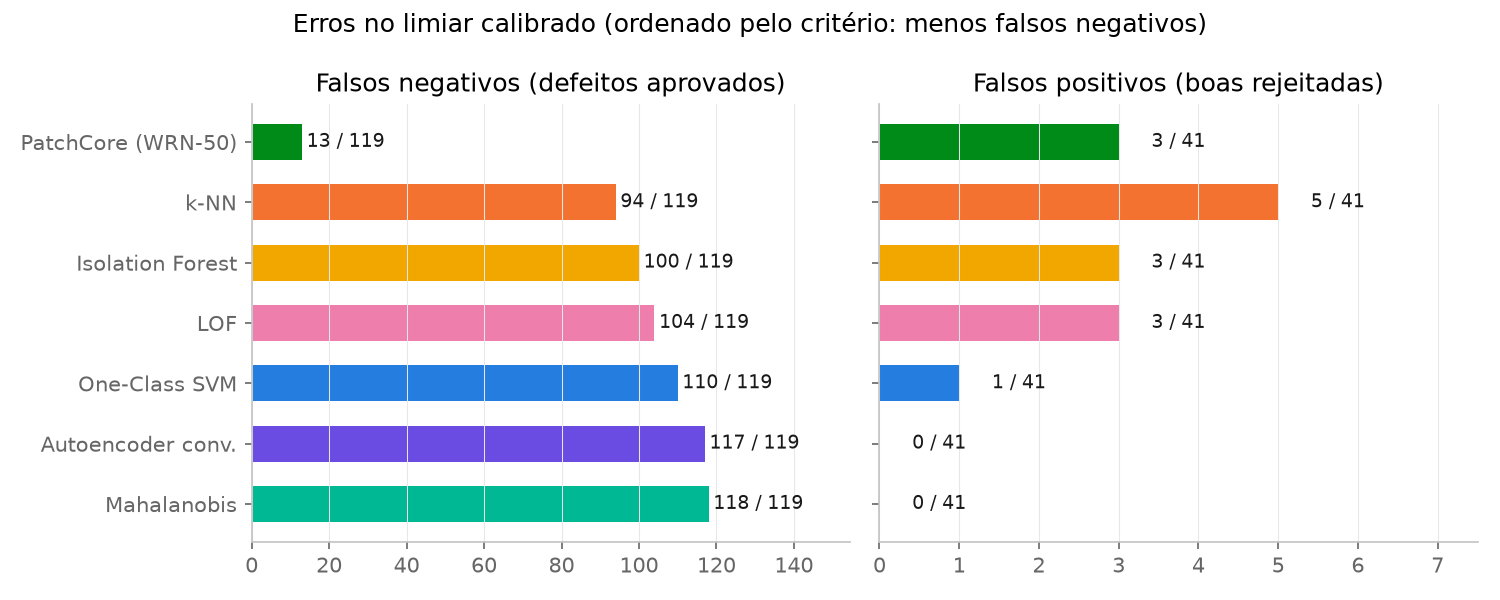

In [4]:
display(Image(AVAL / 'figures/errors_by_model.png'))

## Curvas ROC
O ponto marca o limiar calibrado de cada modelo. A AUC independe do limiar.

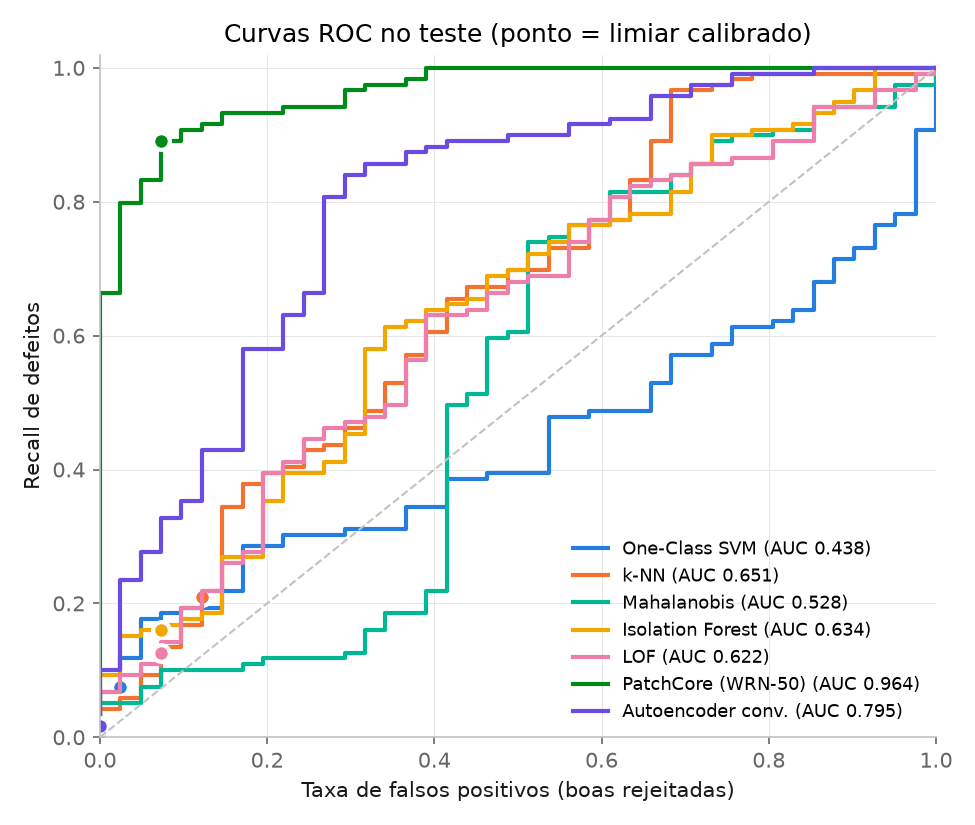

In [5]:
display(Image(AVAL / 'figures/roc_curves.png'))

## Recall por categoria de defeito

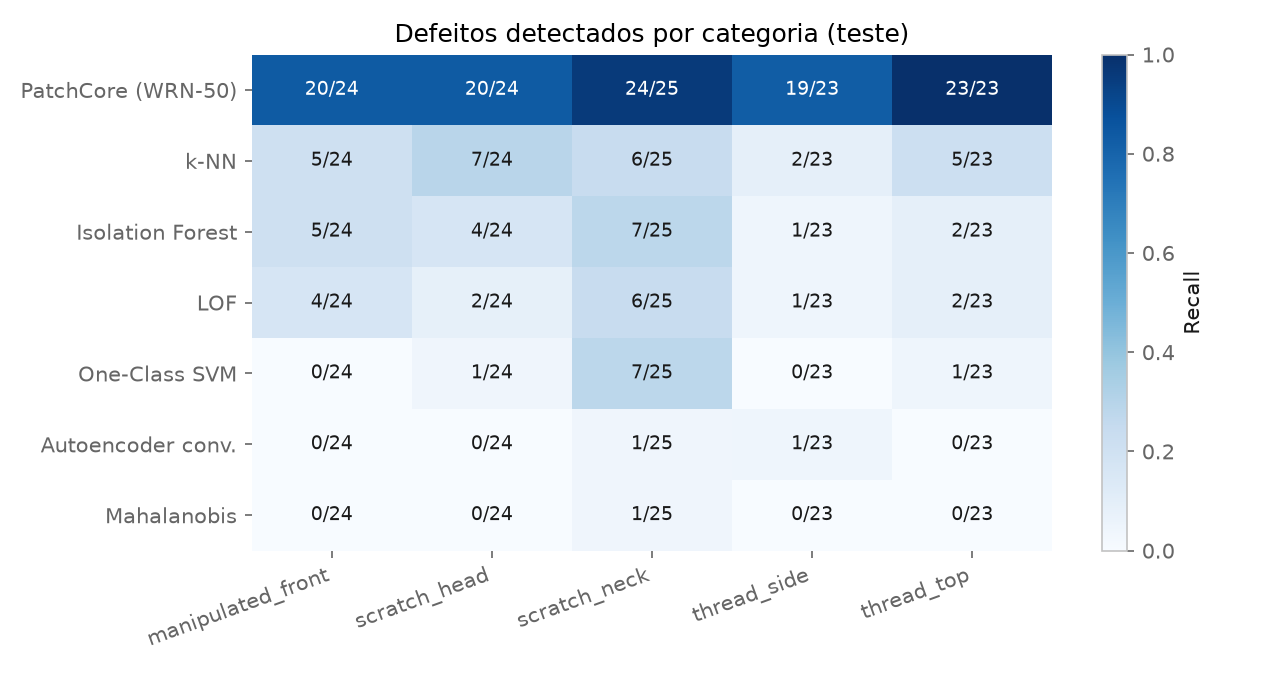

In [6]:
display(Image(AVAL / 'figures/recall_by_category.png'))

## Matrizes de confusão

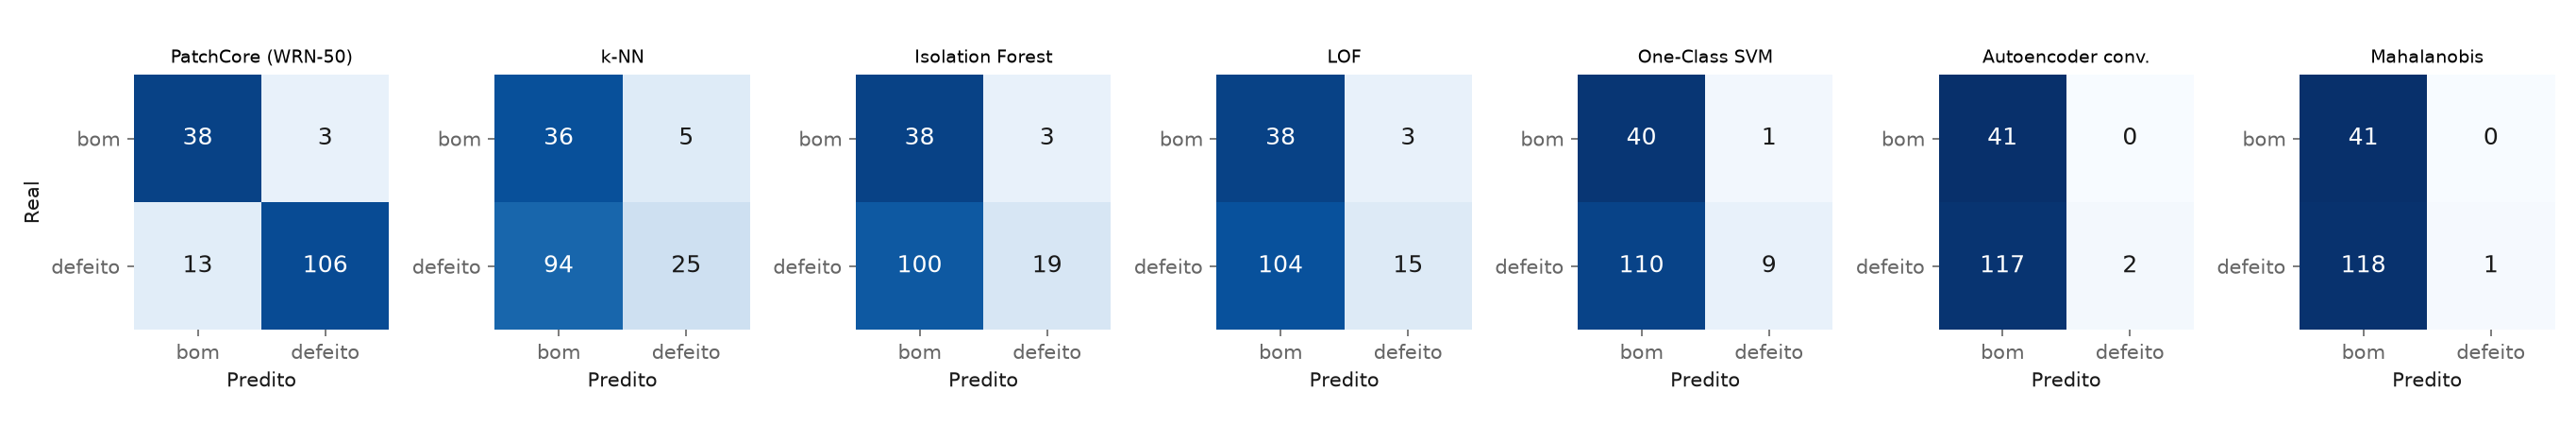

In [7]:
display(Image(AVAL / 'figures/confusion_matrices.png'))

## Distribuição dos scores em relação ao limiar
Pontos à direita da linha tracejada são rejeitados como defeito.

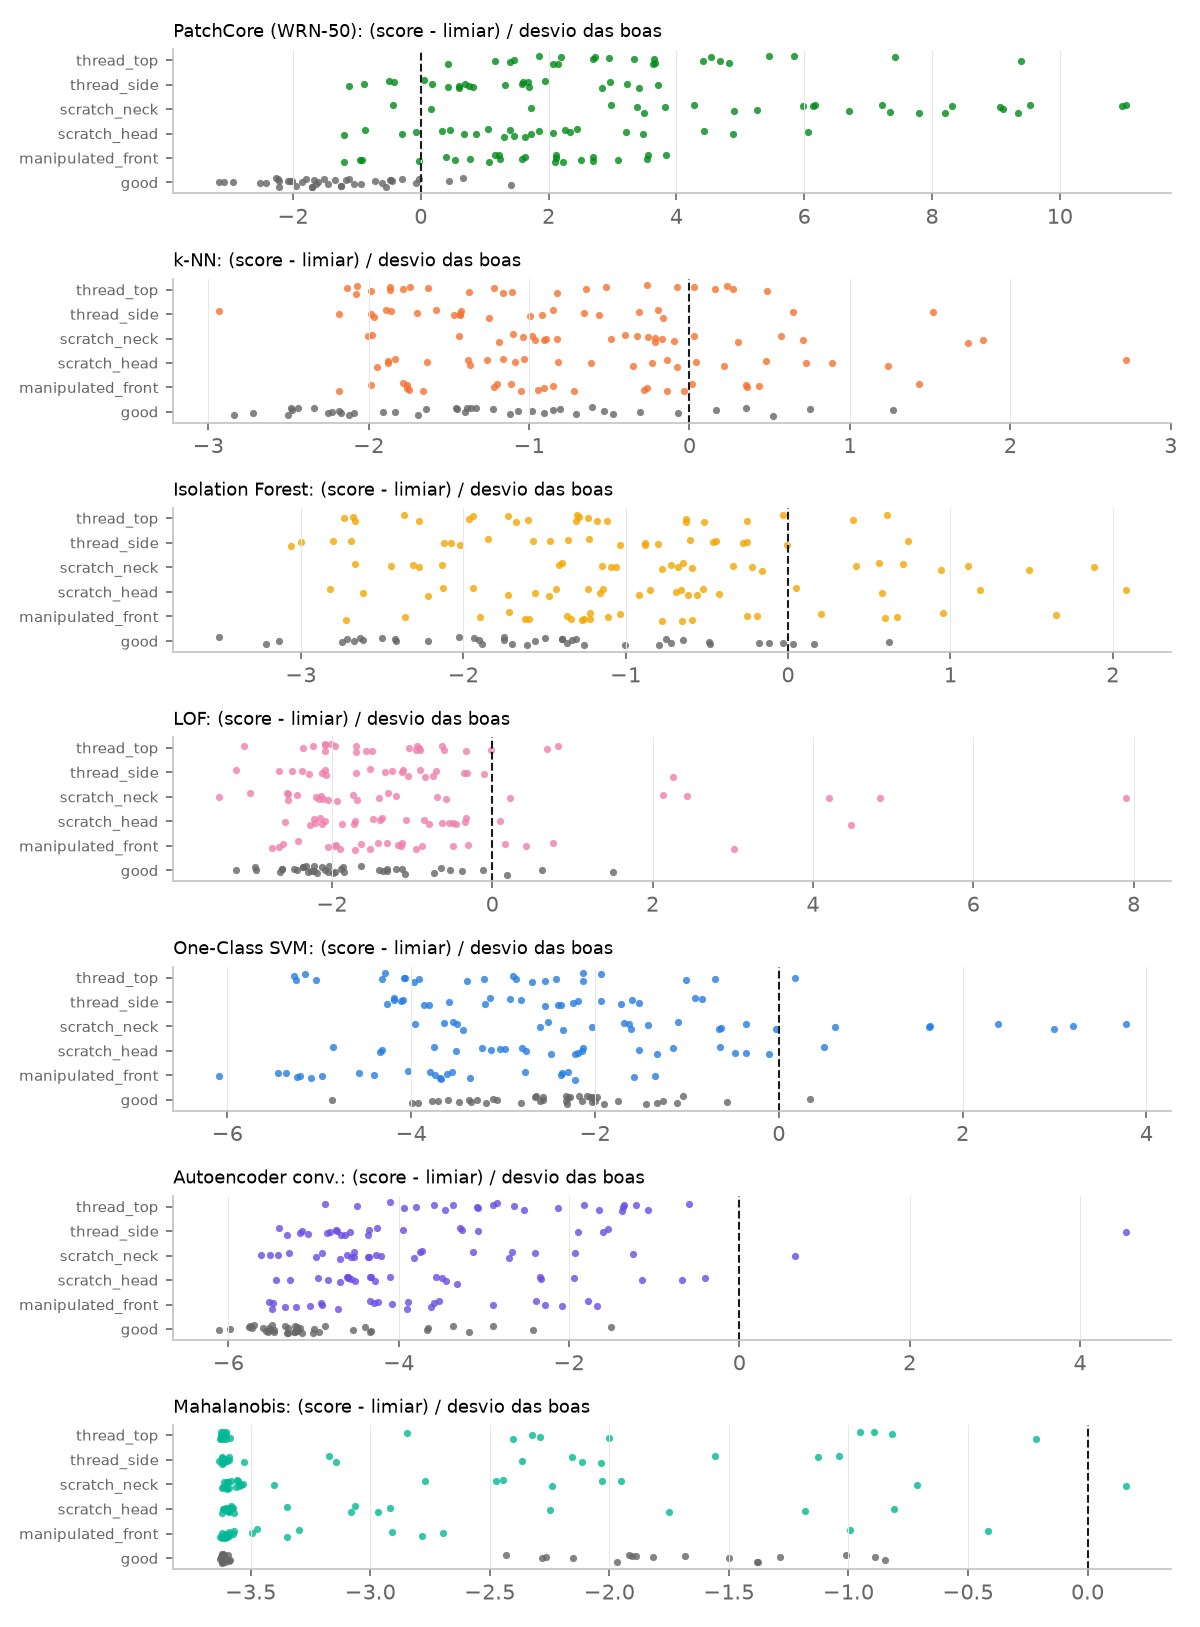

In [8]:
display(Image(AVAL / 'figures/score_distributions.png'))

## Mapas de anomalia do PatchCore
A rede neural também localiza a região suspeita, o que ajuda a interpretar a decisão.

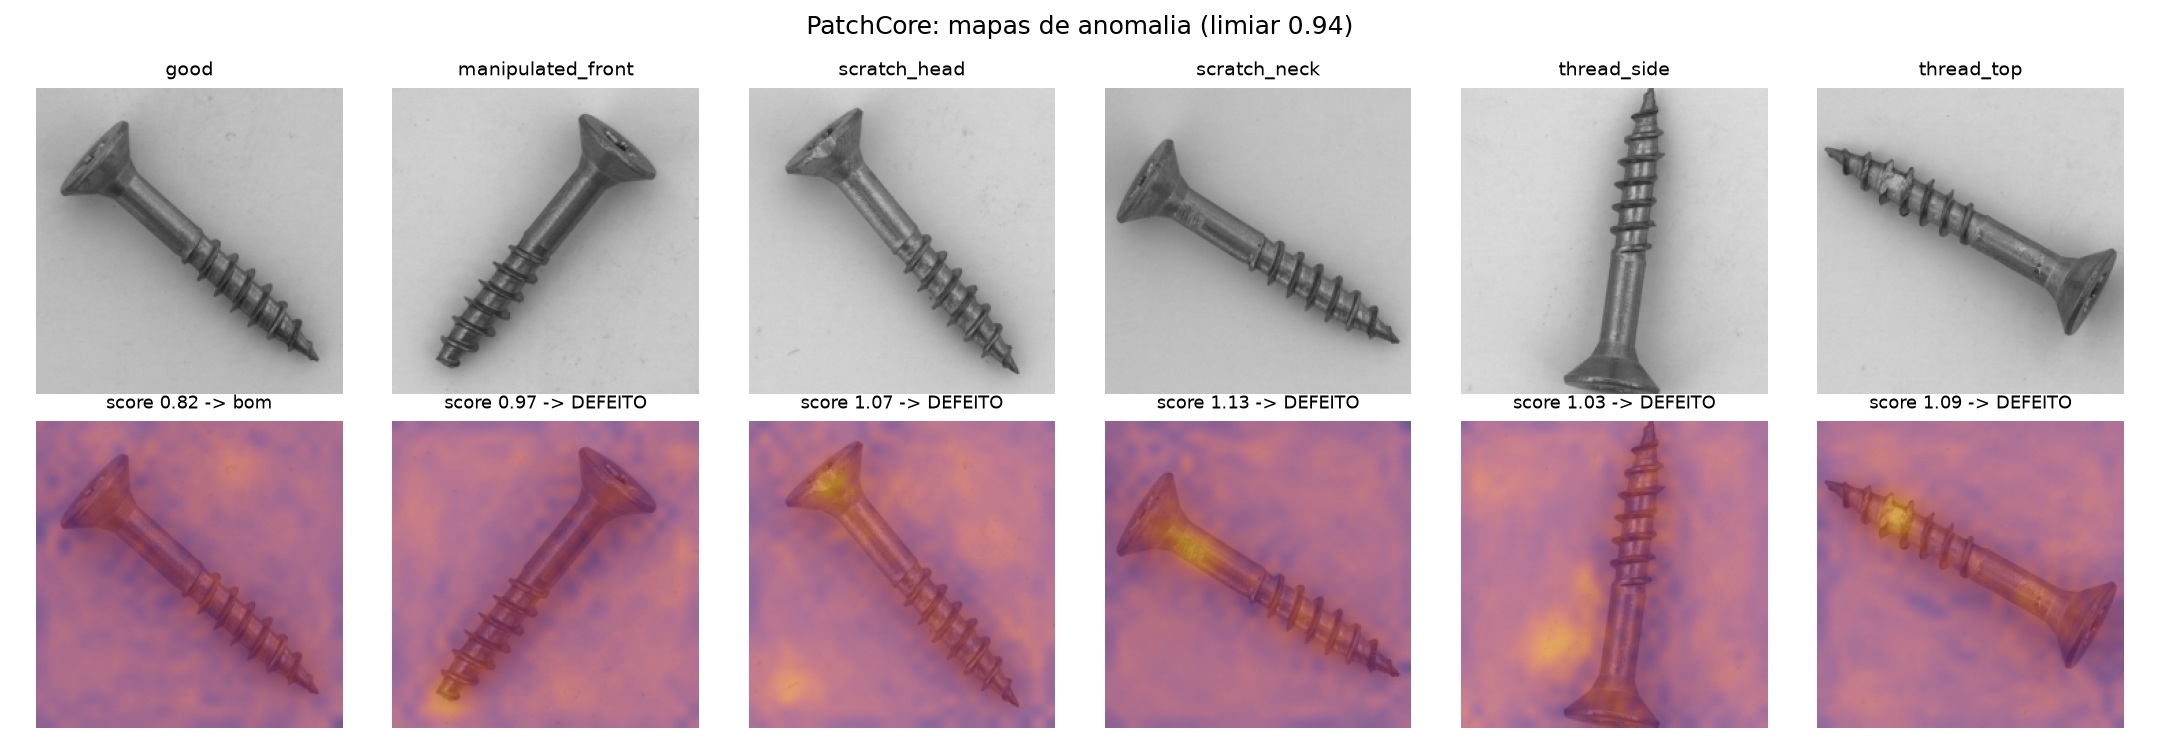

In [9]:
display(Image(AVAL / 'figures/patchcore_heatmaps.png'))

## Análise pós-hoc (descritiva, no teste)
Quantas boas seriam rejeitadas para não deixar passar nenhum defeito, e o recall com especificidade de 95%. Esses números **não** foram usados para escolher limiar nem modelo.

In [10]:
pd.DataFrame({m: r['pos_hoc_no_teste'] for m, r in res['results'].items()}).T

,fp_para_zero_fn,fpr_para_zero_fn,recall_com_especificidade_95
svm,41.0,1.000000,0.176471
knn,41.0,1.000000,0.092437
mahalanobis,41.0,1.000000,0.075630
isolation_forest,38.0,0.926829,0.159664
lof,41.0,1.000000,0.109244
patchcore,16.0,0.390244,0.831933
autoencoder,35.0,0.853659,0.277311


## Verificação de robustez: viés de brilho
As boas de teste são mais escuras que todas as outras imagens; só o brilho separa boas de defeitos do teste com AUC 1,0. Comparar os defeitos com as 64 boas reservadas (mesmo brilho do treino) remove esse viés.

In [11]:
rob = json.loads((ROOT / 'results/stage8/robustness_v1/robustness.json').read_text())
display(pd.DataFrame(rob['brilho_medio_cinza']).T)
print('AUC só com brilho (boas de teste vs defeitos):', rob['auc_brilho_boas_teste_vs_defeitos'])
pd.DataFrame(rob['modelos']).T

,n,media,desvio,min,max
boas_ajuste,256.0,184.178654,5.513489,170.252431,199.836972
boas_reservadas,64.0,184.152794,5.293494,173.318290,196.901298
boas_teste,41.0,170.348907,1.471728,168.220042,173.299900
defeitos_teste,119.0,186.650590,3.237333,176.109446,195.926043


AUC só com brilho (boas de teste vs defeitos): 1.0


,rotulo,familia,auc_teste,auc_reservadas_vs_defeitos,auc_reservadas_vs_boas_teste,correlacao_score_brilho_teste
svm,One-Class SVM,clássico,0.438,0.396928,0.568979,0.033691
knn,k-NN,clássico,0.650953,0.618566,0.546113,0.224638
mahalanobis,Mahalanobis,clássico,0.527567,0.549501,0.463796,-0.030554
isolation_forest,Isolation Forest,clássico,0.634146,0.633666,0.502668,0.21867
lof,LOF,clássico,0.621849,0.561056,0.568216,0.142696
patchcore,PatchCore (WRN-50),rede neural,0.964132,0.979386,0.394817,0.626989
autoencoder,Autoencoder conv.,rede neural,0.795245,0.582589,0.735518,0.322138


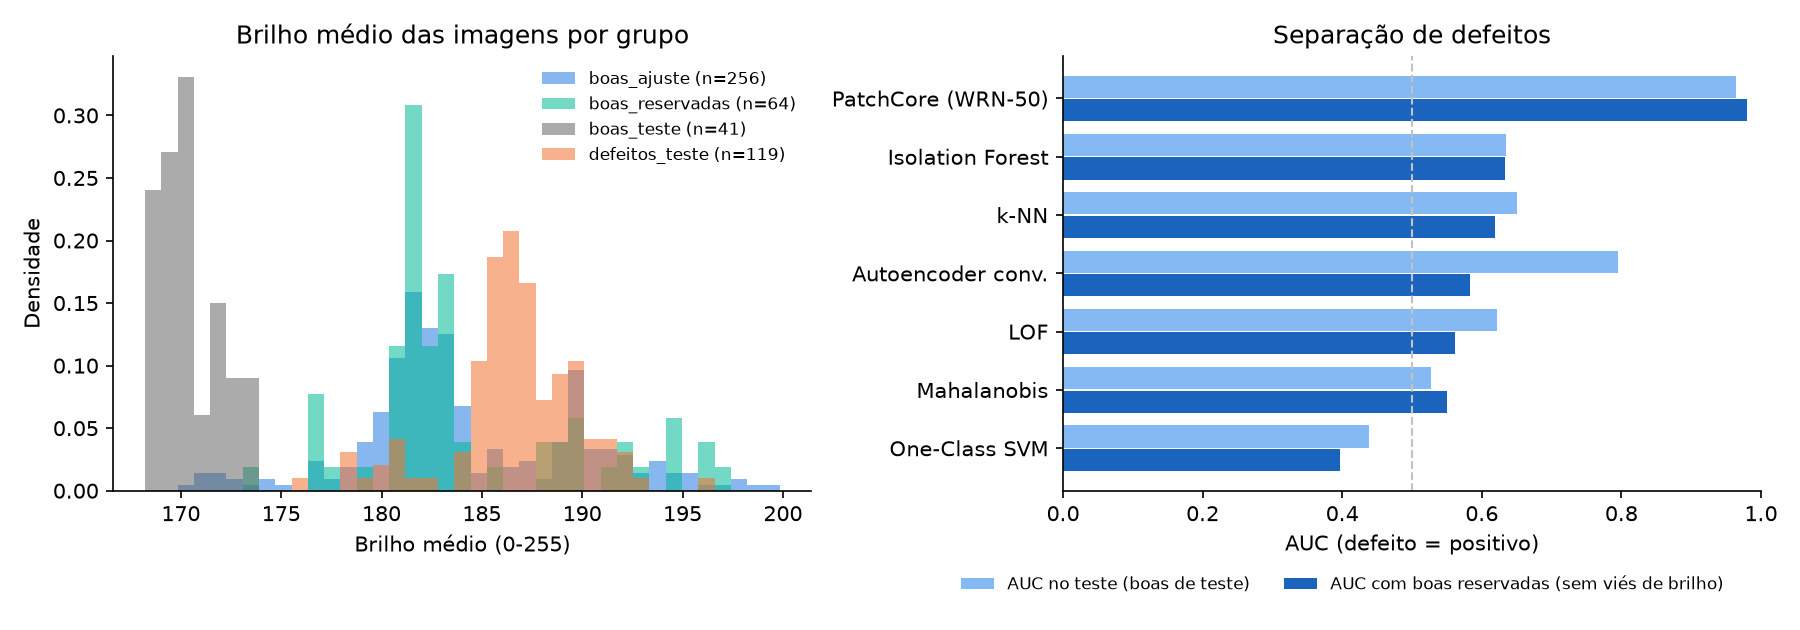

In [12]:
display(Image(ROOT / 'results/stage8/robustness_v1/brightness_robustness.png'))